# CICIDS2017 Intrusion Detector Lab1 
This notebook loads, cleans, trains, evaluates, and saves a binary intrusion detection workflow.

In [27]:
import random
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. Configure the experiment

In [28]:
project_dir = Path.cwd()
data_dir = project_dir / "data"
# Keep full-data runs for final results; sampling is useful when checking code quickly.
USE_SAMPLE = False
SAMPLE_FRAC = 0.25
csv_files = sorted(data_dir.glob("*.csv"))
print(f"Found {len(csv_files)} CSV files in data/")
for path in csv_files:
    print(" -", path.name)


Found 8 CSV files in data/
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv


## 2. Load and clean the CSV files

In [29]:
frames = []
for csv_path in csv_files:
    try:
        # UTF-8 is preferred; the fallback handles the older CICIDS2017 file with Latin-1 bytes.
        frame = pd.read_csv(csv_path, encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        frame = pd.read_csv(csv_path, encoding="latin1", low_memory=False)
        print(f"Used Latin-1 fallback for {csv_path.name}")

    # Normalize headers before looking for Label because some files contain leading spaces.
    frame.columns = [str(col).strip() for col in frame.columns]
    label_col = next((col for col in frame.columns if col.lower() == "label"), None)
    if frame.empty or label_col is None:
        print(f"Skipping {csv_path.name}: no usable label column")
        continue
    if label_col != "Label":
        frame = frame.rename(columns={label_col: "Label"})
    frames.append(frame)

if not frames:
    raise ValueError("No valid CICIDS2017 CSV files were found in the data folder.")

# Combine the valid files into one flow-level dataset for binary classification.
df = pd.concat(frames, ignore_index=True)

# Identifiers and timestamps can identify a capture rather than describe general traffic behavior.
metadata_cols = ["Flow ID", "Source IP", "Destination IP", "Timestamp"]
df = df.drop(columns=[col for col in metadata_cols if col in df.columns], errors="ignore")

# Remove exact duplicates and convert infinite measurements to missing values.
df = df.drop_duplicates().replace([np.inf, -np.inf], np.nan)
for col in df.columns:
    if col != "Label":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# The lab uses binary classification: benign traffic is 0 and every attack type is 1.
df["Label"] = df["Label"].astype(str).str.strip().apply(lambda label: 0 if label == "BENIGN" else 1)
if USE_SAMPLE:
    df = df.sample(frac=SAMPLE_FRAC, random_state=SEED)
print("Cleaned dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nLabel distribution:")
print(df["Label"].value_counts().sort_index())

# Plot binary class distribution
label_counts = df["Label"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Benign", "Attack"],
    [
        label_counts.get(0, 0),
        label_counts.get(1, 0)
    ]
)

plt.xlabel("Class")
plt.ylabel("Number of Flows")
plt.title("CICIDS2017 Binary Class Distribution")

# Disable scientific notation on Y-axis
plt.ticklabel_format(
    style="plain",
    axis="y"
)

# Add exact count above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Used Latin-1 fallback for Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv


KeyboardInterrupt: 

## 3. Create stratified train, validation, and test sets

In [ ]:
X = df.drop(columns=["Label"])
y = df["Label"].astype(int)
# Stratification keeps the benign/attack ratio similar in all three partitions.
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

total = len(X)
print(f"Train: {len(X_train)} ({len(X_train)/total:.1%})")
print(f"Val:   {len(X_val)} ({len(X_val)/total:.1%})")
print(f"Test:  {len(X_test)} ({len(X_test)/total:.1%})")
print("\nClass balance per split (proportion of attacks, Label=1):")
print(f"Train: {y_train.mean():.3f}")
print(f"Val:   {y_val.mean():.3f}")
print(f"Test:  {y_test.mean():.3f}")

Train: 1688280 (60.0%)
Val:   562760 (20.0%)
Test:  562760 (20.0%)

Class balance per split (proportion of attacks, Label=1):
Train: 0.195
Val:   0.195
Test:  0.195


## 4. Define evaluation metrics

In [ ]:
def compute_binary_metrics(y_true, y_pred, y_proba=None):
    # FAR measures the proportion of benign flows incorrectly flagged as attacks.
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "attack_f1": f1_score(y_true, y_pred, zero_division=0),
        "far": fp / (fp + tn) if (fp + tn) else 0.0,
        "roc_auc": roc_auc_score(y_true, y_proba) if y_proba is not None else np.nan,
    }

## 5. Preprocessing of models

In [ ]:
# Each pipeline learns medians from X_train only, preventing validation/test leakage.
median_imputer = SimpleImputer(strategy="median", keep_empty_features=True)
models = {
    "Logistic Regression": Pipeline([("imputer", median_imputer), ("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=SEED, class_weight="balanced"))]),
    "Random Forest": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, class_weight="balanced", n_jobs=-1))]),
    "MLP": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scaler", StandardScaler()), ("model", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=SEED))]),
}

## 6. Train and compare models on validation data

In [ ]:
validation_results = {}
for name, model in models.items():
    # Use validation F1 to choose a model before looking at final test performance.
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    val_proba = model.predict_proba(X_val)[:, 1]
    validation_results[name] = compute_binary_metrics(y_val, val_pred, val_proba)
best_model_name = max(validation_results, key=lambda key: validation_results[key]["macro_f1"])
print("Best validation model by F1:", best_model_name)
print(pd.DataFrame(validation_results).T.sort_values("macro_f1", ascending=False))

Best validation model by F1: Random Forest
                     accuracy  precision    recall  macro_f1  attack_f1       far   roc_auc
Random Forest        0.999593   0.998601  0.999318  0.999353   0.998960  0.000340  0.999986
MLP                  0.996229   0.986622  0.994191  0.994023   0.990392  0.003276  0.999873
Logistic Regression  0.919276   0.718003  0.966729  0.885816   0.824006  0.092253  0.980116


## 7. Evaluate models on the held-out test set

In [ ]:
# The test set remains untouched until this final evaluation stage.
test_results = {}
for name, model in models.items():
    test_pred = model.predict(X_test)
    test_proba = model.predict_proba(X_test)[:, 1]
    test_results[name] = compute_binary_metrics(y_test, test_pred, test_proba)
summary = pd.DataFrame(test_results).T.sort_values("macro_f1", ascending=False)
print(summary)

                     accuracy  precision    recall  macro_f1  attack_f1       far   roc_auc
Random Forest        0.999606   0.998601  0.999382  0.999373   0.998991  0.000340  0.999987
MLP                  0.996261   0.986668  0.994309  0.994074   0.990474  0.003264  0.999876
Logistic Regression  0.919420   0.718437  0.966602  0.885986   0.824245  0.092044  0.979783


## 8. AUC-ROC curve plot

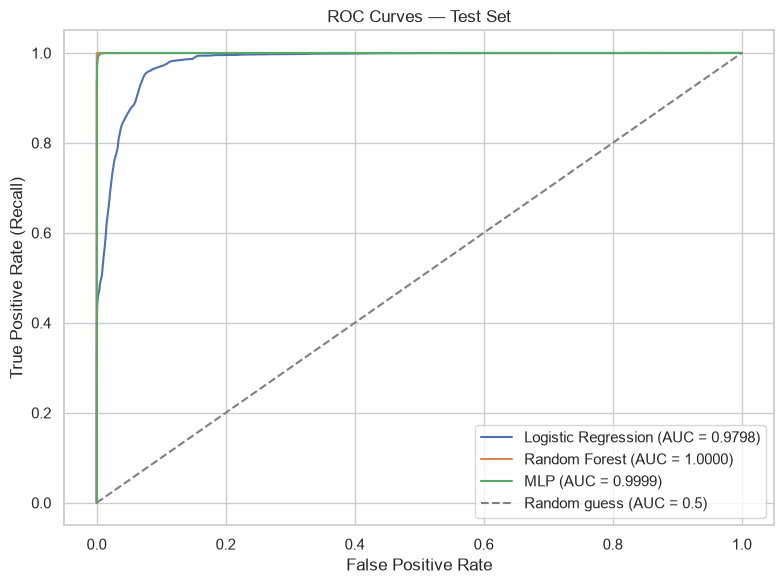

In [30]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    auc_score = test_results[name]["roc_auc"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})")

# Diagonal reference line = random guessing (AUC = 0.5)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC = 0.5)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — Test Set")
plt.legend(loc="lower right")
plt.tight_layout()

fig_dir = project_dir / "figures"
fig_dir.mkdir(exist_ok=True)
plt.savefig(fig_dir / "roc_curves.png", dpi=150)
plt.show()

## 9. Run the scaling ablation study

In [ ]:
# ============================================================
# Ablation study: feature scaling ON vs. OFF, across all three models
# Everything else (imputer strategy, model hyperparameters, seed,
# train/val split) is held identical — only the presence of
# StandardScaler in the pipeline changes.
# ============================================================

model_configs = {
    "Logistic Regression": lambda: LogisticRegression(
        max_iter=2000, random_state=SEED, class_weight="balanced"
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=300, random_state=SEED, class_weight="balanced", n_jobs=-1
    ),
    "MLP": lambda: MLPClassifier(
        hidden_layer_sizes=(64, 32), max_iter=500, random_state=SEED
    ),
}

# --- Compute "without scaling" results fresh ---
noscale_results = {}
for name, make_model in model_configs.items():
    pipe_noscale = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("model", make_model()),
    ])
    pipe_noscale.fit(X_train, y_train)
    pred = pipe_noscale.predict(X_val)
    proba = (
        pipe_noscale.predict_proba(X_val)[:, 1]
        if hasattr(pipe_noscale, "predict_proba") else None
    )
    noscale_results[name] = compute_binary_metrics(y_val, pred, proba)

metrics_to_compare = ["accuracy", "macro_f1", "recall", "roc_auc", "far"]

# --- Build long-format table: one row per (model, scaling) ---
rows = []
for name in model_configs:
    rows.append({
        "model": name,
        "scaling": "with scaling",
        **{m: validation_results[name][m] for m in metrics_to_compare},
    })
    rows.append({
        "model": name,
        "scaling": "without scaling",
        **{m: noscale_results[name][m] for m in metrics_to_compare},
    })

ablation_table = pd.DataFrame(rows).set_index(["model", "scaling"])

print("Ablation: scaling ON vs. OFF (validation set)\n")
print(ablation_table)

# Save for the report
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)
ablation_table.to_csv(results_dir / "ablation_scaling.csv")
print("\nSaved ablation table to:", results_dir / "ablation_scaling.csv")

Ablation: scaling ON vs. OFF (validation set)

                                     accuracy  macro_f1    recall   roc_auc       far
model               scaling                                                          
Logistic Regression with scaling     0.919276  0.885816  0.966729  0.980116  0.092253
                    without scaling  0.851265  0.779470  0.717954  0.882354  0.116344
Random Forest       with scaling     0.999593  0.999353  0.999318  0.999986  0.000340
                    without scaling  0.999593  0.999353  0.999318  0.999986  0.000340
MLP                 with scaling     0.996229  0.994023  0.994191  0.999873  0.003276
                    without scaling  0.804522  0.445837  0.000000  0.696829  0.000000

Saved ablation table to: /Users/natashadonner/Documents/LTU/D7084E/D7084E_XAI_Lab1/results/ablation_scaling.csv


## 10. Save feature importance and metrics

In [ ]:
# Read feature importance from the fitted Random Forest inside its preprocessing pipeline.
rf_model = models["Random Forest"].named_steps["model"]
feature_importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(feature_importance.head(10))
# Save artifacts separately so results can be inspected without rerunning training.
fig_dir = project_dir / "figures"
fig_dir.mkdir(exist_ok=True)
feature_importance.head(15).sort_values().plot(kind="barh", figsize=(10, 6), color="steelblue")
plt.title("Top 15 features for CICIDS2017 attack detection")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(fig_dir / "top_features.png", dpi=150)
plt.close()
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)
summary.to_csv(results_dir / "model_metrics.csv")
print("Saved metrics to:", results_dir / "model_metrics.csv")
print("Saved feature plot to:", fig_dir / "top_features.png")

Destination Port           0.059619
Average Packet Size        0.051085
Source Port                0.049661
Packet Length Std          0.049638
Init_Win_bytes_forward     0.043998
Packet Length Variance     0.042860
Init_Win_bytes_backward    0.039898
Min Packet Length          0.034337
Max Packet Length          0.031968
Fwd Packet Length Min      0.031044
dtype: float64
Saved metrics to: /Users/natashadonner/Documents/LTU/D7084E/D7084E_XAI_Lab1/results/model_metrics.csv
Saved feature plot to: /Users/natashadonner/Documents/LTU/D7084E/D7084E_XAI_Lab1/figures/top_features.png
